# CropGuard-Q: a quantum crop checker under attack

**Moroccan Crop Classification Challenge · Qiskit Fall Fest · EMSI × Quantum Africa** — classify Doukkala fields as **alfalfa, maize or wheat** from Sentinel-2 measurements, and answer one focused question:

> **Does adding a quantum model to a classical model add anything, especially when the data is tampered with or incomplete, compared with adding another classical model instead?**

**Run it** from the repository root (Python 3.12 as pinned; also tested on CPython 3.15):

```bash
python3.12 -m venv .venv
.venv/bin/python -m pip install -r requirements.txt         # main run
.venv/bin/python -m pip install -r requirements-noise.txt   # optional: section 6 (noise study)
.venv/bin/jupyter nbconvert --to notebook --execute --inplace notebooks/CropGuard_Q.ipynb
```

Sections 1–4 are the **main result**: exact local simulation, no network, no credentials, no optional package. Sections 5–7 are **additional analysis**; each can be switched off in the next cell, and the IBM section only reads saved results unless `RUN_HARDWARE = True`. Every number in the text is produced by the cells (section 8 is written by `challenge/report.py`); every parameter comes from `configs/experiment.json`, the data's own facts from `data/manifest.json`, and the selected settings from `configs/cropguard.json`. [`docs/GUIDE.md`](../docs/GUIDE.md) explains every function used here.

| Part | What it does |
|---|---|
| Quantum inspector | ZZ-feature-map fidelity kernel, one qubit per PCA number, exact statevectors, then an SVM with a precomputed kernel |
| Classical inspectors | RBF SVM and random forest on the same numbers |
| Vote + tamper alarm | majority label (the RBF SVM settles a three-way split); a field is **flagged** when the three are not unanimous |
| Matched control | the same pipeline with the quantum SVM replaced by a polynomial-kernel SVM tuned with a grid of the same size |
| AI error-fixer | a linear regression that maps noisy similarity values back to exact ones; used for the noisy-simulator and IBM runs |

In [1]:
import json, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from challenge.config import EXPERIMENT, FEATURES, LABELS, MANIFEST, QUBITS
from challenge.data import load_data
from challenge.classical import reference
from challenge.metrics import score
from challenge.submission import Submission, MatchedControl, load_config, preprocessing
from challenge.kernel import QuantumKernelSVM
from challenge import guard, tune, mitigation, report, hardware_kernel as hk  # hardware_kernel imports IBM code only when used

RUN_TUNING = True       # ~1 min: reruns the grid search; the frozen configs/cropguard.json is used either way
RUN_ATTACK_LAB = True   # several minutes: tampering, poisoned labels, missing bands (additional analysis)
RUN_NOISE_STUDY = True  # a few minutes, needs requirements-noise.txt; otherwise the saved study is shown
RUN_HARDWARE = False    # needs requirements-hardware.txt, QISKIT_IBM_TOKEN and approval; otherwise saved results are shown

OUT = ROOT / 'outputs'; (OUT / 'predictions').mkdir(parents=True, exist_ok=True)
L, SEEDS = list(LABELS), EXPERIMENT['seeds']
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.grid': True, 'grid.alpha': .3})
def save_show(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight'); plt.show()
def timed(fn):
    t = time.perf_counter(); out = fn(); return out, time.perf_counter() - t
T0 = time.perf_counter()

tables, _, manifest, _ = load_data()  # verifies every checksum, schema and split before anything else
X, y = tables['train'][FEATURES].to_numpy(), tables['train'].target.to_numpy()
Xv, yv = tables['validation'][FEATURES].to_numpy(), tables['validation'].target.to_numpy()
Xt = tables['test'][FEATURES].to_numpy()  # test features only: no test label exists anywhere in this repository
ids_v, ids_t = tables['validation'].sample_id.to_numpy(), tables['test'].sample_id.to_numpy()
print('Python', sys.version.split()[0], '| rows', MANIFEST['rows'], '| imagery', MANIFEST['observation_date'],
      '| survey', MANIFEST['survey_date_range'], '| qubits', QUBITS, '| inputs', FEATURES)

Python 3.15.2 | rows {'train': 914, 'validation': 150, 'test': 221} | imagery 2024-04-25 | survey ['2024-04-23', '2024-04-27'] | qubits 8 | inputs ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'NDVI']


## 1. Inputs and preprocessing

Every model receives the raw features listed in `data/manifest.json` (never IDs or spatial codes). `Submission.fit` learns `StandardScaler → PCA(qubits) → StandardScaler` on the training rows only, one PCA number per qubit; with 8 qubits this is the recipe of the supplied `data/views/pca8.npz`, and the check below confirms an exact match. The last components carry very little variance and the second scaler stretches them to unit size; section 5 shows that this is where tampering attacks push.

In [2]:
prep = preprocessing().fit(X)
view_file = ROOT / f'data/views/pca{QUBITS}.npz'
if view_file.exists():
    view = np.load(view_file, allow_pickle=False)
    assert np.allclose(prep.transform(X), view['X_train']) and np.allclose(prep.transform(Xv), view['X_validation'])
    assert np.allclose(prep.transform(Xt), view['X_test'])
    print(f'matches the supplied {view_file.name} exactly')
pca = prep[1]
pca_table = pd.DataFrame({'explained variance': pca.explained_variance_ratio_.round(4),
                          'stretch by 2nd scaler (vs PC1)': np.sqrt(pca.explained_variance_[0] / pca.explained_variance_).round(1)},
                         index=[f'PC{i+1}' for i in range(QUBITS)]).T
display(pca_table)

matches the supplied pca8.npz exactly


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
explained variance,0.5256,0.3714,0.0659,0.0283,0.004,0.0019,0.0013,0.001
stretch by 2nd scaler (vs PC1),1.0000,1.2000,2.8000,4.3000,11.500,16.8000,20.4000,22.800


## 2. Settings: equal tuning budget, chosen on validation, then frozen

Each inspector gets **a grid of the same size** (`configs/experiment.json`, `tuning.grids`), scored by validation macro-F1, ties to the simpler entry ([`challenge/tune.py`](../challenge/tune.py)). The winners are frozen in [`configs/cropguard.json`](../configs/cropguard.json) before any test prediction. Because the same validation fields choose and score the settings, all validation numbers below are optimistic, equally for the quantum model and its controls.

The quantum kernel has one sensitive knob, the **rotation strength** `scale` that multiplies the inputs before they become angles. Too strong a rotation makes every field look unlike every other (kernel collapse).

quantum  30 configs    2.9s  best {'scale': 0.075, 'C': 100}  F1 0.9200


poly     30 configs    1.0s  best {'degree': 3, 'coef0': 2, 'C': 1}  F1 0.9269


rbf      30 configs    0.9s  best {'gamma': 0.06, 'C': 30}  F1 0.9326


forest   30 configs   26.2s  best {'max_features': 2, 'min_samples_leaf': 2}  F1 0.9130


rerun reproduces the frozen settings: True


,frozen_settings,configurations,tuning_seconds,best_validation_macro_f1
quantum,"{'scale': 0.075, 'C': 100}",30,2.9,0.92
poly,"{'degree': 3, 'coef0': 2, 'C': 1}",30,1.0,0.9269
rbf,"{'gamma': 0.06, 'C': 30}",30,0.9,0.9326
forest,"{'max_features': 2, 'min_samples_leaf': 2}",30,26.2,0.913


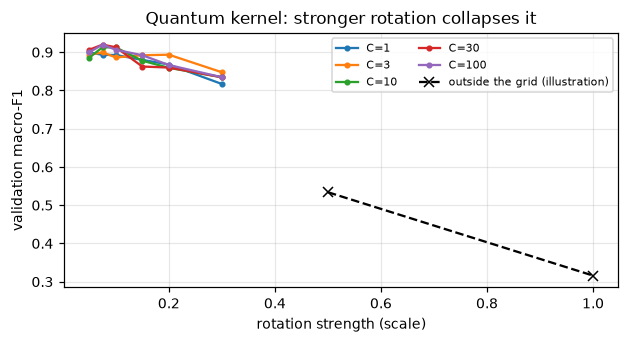

outside the grid -> {0.5: 0.534, 1.0: 0.316}


In [3]:
config = load_config()
if RUN_TUNING:
    rerun, log = tune.tune(write=False)
    print('rerun reproduces the frozen settings:', all(rerun[k] == config[k] for k in tune.GRIDS))
else:
    log = json.loads((OUT / 'tuning_log.json').read_text())
display(pd.DataFrame({k: dict(frozen_settings=config[k], configurations=v['configurations'], tuning_seconds=round(v['seconds'], 1),
                              best_validation_macro_f1=round(v['best_validation_macro_f1'], 4)) for k, v in log.items()}).T)

grid = pd.DataFrame(log['quantum']['rows'])
Z, Zv = prep.transform(X), prep.transform(Xv)
outside = {s: score(yv, QuantumKernelSVM(s, config['quantum']['C']).fit(Z, y).predict(Zv), L)['macro_f1']
           for s in EXPERIMENT['tuning']['illustration_scales']}
fig, ax = plt.subplots(figsize=(6.5, 3))
for C, g in grid.groupby('C'): ax.plot(g.scale, g.validation_macro_f1, marker='o', ms=3, label=f'C={C}')
ax.plot(list(outside), list(outside.values()), 'kx--', label='outside the grid (illustration)')
ax.set(xlabel='rotation strength (scale)', ylabel='validation macro-F1', title='Quantum kernel: stronger rotation collapses it')
ax.legend(fontsize=7, ncol=2); save_show(fig, 'cg_01_kernel_scale')
print('outside the grid ->', {k: round(v, 3) for k, v in outside.items()})

## 3. Main result: every seed on validation, then frozen test predictions

The quantum-kernel SVM, the RBF SVM and the polynomial SVM are **deterministic**, so their results repeat across seeds; only the forest (and therefore the committees) depends on the seed. Times include preprocessing, statevector simulation, kernel construction and fitting. The supplied classical reference is refitted and checked against `results/reference_0_predictions.csv`.

In [4]:
ref, ref_fit = timed(lambda: reference().fit(X, y))
ref_pred, ref_predict = timed(lambda: ref.predict(Xv))
supplied = pd.read_csv(ROOT / 'results/reference_0_predictions.csv').set_index('sample_id').loc[ids_v]
assert (supplied.prediction.to_numpy() == ref_pred).all(), 'refitted reference differs from the supplied run'

records, P, fitted = [], {}, {}
def record(name, seed, pred, **extra):
    P[name, seed] = pred
    records.append(dict(model=name, seed=seed, **score(yv, pred, L), **extra))
    pd.DataFrame({'sample_id': ids_v, 'target': yv, 'prediction': pred}).to_csv(
        OUT / 'predictions' / f"{name.replace(' ', '_')}_{seed}_validation.csv", index=False)

names = {'quantum': 'quantum SVM', 'poly': 'poly SVM', 'rbf': 'RBF SVM', 'forest': 'forest'}
for seed in SEEDS:
    record('reference', seed, ref_pred, fit_seconds=ref_fit, predict_seconds=ref_predict)
    for name, cls in [('quantum committee', Submission), ('matched control', MatchedControl)]:
        model, fit_s = timed(lambda: cls().fit(X, y, seed))
        ins, pred_s = timed(lambda: model.inspect(Xv))
        fitted[name, seed] = model
        record(name, seed, ins['prediction'], fit_seconds=fit_s, predict_seconds=pred_s, flagged=ins['flag'].mean(),
               accuracy_unflagged=(ins['prediction'] == yv)[~ins['flag']].mean())
        for member, votes in zip(model.names, ins['votes']):
            if (names[member], seed) not in P: record(names[member], seed, votes, fit_seconds=model.fit_seconds[member])
        test = model.inspect(Xt)  # frozen settings, test features only
        pd.DataFrame({'sample_id': ids_t, 'prediction': test['prediction'], 'flag': test['flag'],
                      **{m: v for m, v in zip(model.names, test['votes'])}}).to_csv(
            OUT / 'predictions' / f"{name.replace(' ', '_')}_{seed}_test.csv", index=False)

runs = pd.DataFrame(records)
order = ['quantum committee', 'matched control', 'reference', 'quantum SVM', 'poly SVM', 'RBF SVM', 'forest']
for k, c in enumerate(L):
    runs[f'recall_{c}'] = runs.recall.str[k]; runs[f'precision_{c}'] = runs.precision.str[k]
cols = ['macro_f1', 'accuracy'] + [f'recall_{c}' for c in L] + [f'precision_{c}' for c in L] + ['flagged', 'accuracy_unflagged', 'fit_seconds', 'predict_seconds']
summary = runs.groupby('model')[cols].agg(['mean', lambda s: s.std(ddof=0)]).rename(columns={'<lambda_0>': 'sd'}).loc[order]
display(summary[['macro_f1', 'accuracy', 'flagged', 'accuracy_unflagged', 'fit_seconds']].round(4))
display(summary[[f'recall_{c}' for c in L] + [f'precision_{c}' for c in L]].xs('mean', axis=1, level=1).round(3))

macro_f1         accuracy         flagged          \
                      mean      sd     mean      sd    mean      sd   
model                                                                 
quantum committee   0.9214  0.0033   0.9222  0.0031  0.0911  0.0031   
matched control     0.9218  0.0032   0.9222  0.0031  0.0844  0.0031   
reference           0.8797  0.0000   0.8800  0.0000     NaN     NaN   
quantum SVM         0.9200  0.0000   0.9200  0.0000     NaN     NaN   
poly SVM            0.9269  0.0000   0.9267  0.0000     NaN     NaN   
RBF SVM             0.9326  0.0000   0.9333  0.0000     NaN     NaN   
forest              0.9040  0.0063   0.9044  0.0063     NaN     NaN   

                  accuracy_unflagged         fit_seconds          
                                mean      sd        mean      sd  
model                                                             
quantum committee             0.9633  0.0001      0.8079  0.0809  
matched control               0.9636  0.0001      0.7025  0.0188  
reference                        NaN     NaN      0.0177  0.0000  
quantum SVM                      NaN     NaN      0.1010  0.0169  
poly SVM                         NaN     NaN      0.0308  0.0051  
RBF SVM                          NaN     NaN      0.0293  0.0069  
forest                           NaN     NaN      0.6740  0.0566

,recall_alfalfa,recall_maize,recall_wheat,precision_alfalfa,precision_maize,precision_wheat
model,,,,,,
quantum committee,0.940,0.980,0.847,0.922,0.913,0.934
matched control,0.940,0.960,0.867,0.922,0.929,0.915
reference,0.940,0.860,0.840,0.887,0.915,0.840
quantum SVM,0.940,0.920,0.900,0.922,0.939,0.900
poly SVM,0.940,0.920,0.920,0.959,0.939,0.885
RBF SVM,0.960,0.980,0.860,0.941,0.925,0.935
forest,0.933,0.933,0.847,0.921,0.909,0.882


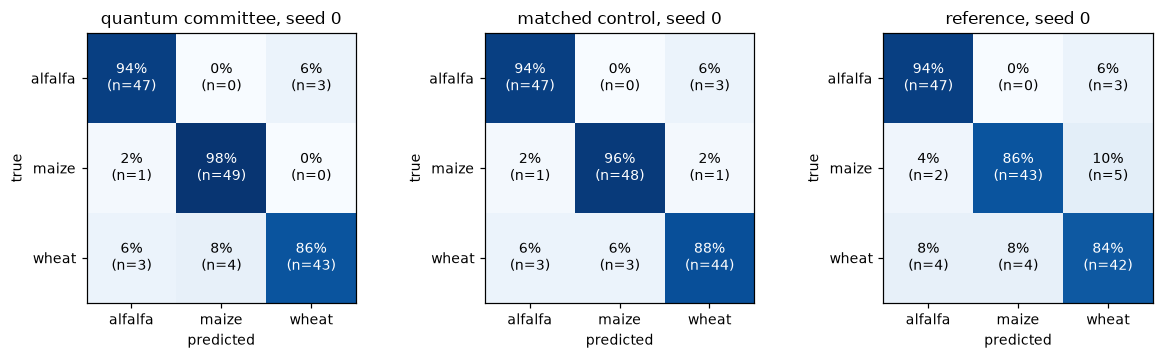

,qubits,feature_map_depth,feature_map_cx,kernel_circuit_cx,trainable_quantum,support_vectors,training_states_simulated,training_kernel_circuits,circuits_per_predicted_field,kernel_storage_bytes,dual_coefficients,simulation,params,stored_values,trees,total_nodes,mean_depth
quantum · quantum,8,23,14,28,0,222,914,417241,222,6683168,444,exact statevector,"{'scale': 0.075, 'C': 100}",NaN,NaN,NaN,NaN
quantum · rbf,NaN,NaN,NaN,NaN,NaN,200,NaN,NaN,NaN,NaN,NaN,NaN,"{'gamma': 0.06, 'C': 30}",2000,NaN,NaN,NaN
quantum · forest,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{'max_features': 2, 'min_samples_leaf': 2}",NaN,300,40454,11.233333333333333
control · poly,NaN,NaN,NaN,NaN,NaN,190,NaN,NaN,NaN,NaN,NaN,NaN,"{'degree': 3, 'coef0': 2, 'C': 1}",1900,NaN,NaN,NaN
control · rbf,NaN,NaN,NaN,NaN,NaN,200,NaN,NaN,NaN,NaN,NaN,NaN,"{'gamma': 0.06, 'C': 30}",2000,NaN,NaN,NaN
control · forest,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{'max_features': 2, 'min_samples_leaf': 2}",NaN,300,40454,11.233333333333333


**Resources.** The quantum member uses **8 qubits**, a feature map of depth 23 with 14 CX gates (a kernel circuit is the map followed by its inverse: 28 CX before compilation), **0 trainable quantum angles** and 222 support vectors. Exact simulation computes one 256-amplitude statevector per field (914 for training) instead of the 417,241 compute-uncompute circuits a QPU would need for the training kernel; predicting one field on a QPU takes 222 circuits, one per support vector. Training kernel: 6.7 MB. Preprocessing stores 159 fitted values. Parameter matching is not required for kernels and trees, so support vectors, stored values, tree nodes and runtime are reported instead.

In [5]:
from sklearn.metrics import confusion_matrix
first = SEEDS[0]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, name in zip(axes, ['quantum committee', 'matched control', 'reference']):
    cm = confusion_matrix(yv, P[name, first], labels=L); norm = cm / cm.sum(1, keepdims=True)
    ax.imshow(norm, vmin=0, vmax=1, cmap='Blues'); ax.grid(False)
    for i in range(len(L)):
        for j in range(len(L)): ax.text(j, i, f'{norm[i, j]:.0%}\n(n={cm[i, j]})', ha='center', va='center', color='white' if norm[i, j] > .55 else 'black')
    ax.set(xticks=range(len(L)), yticks=range(len(L)), xticklabels=L, yticklabels=L, xlabel='predicted', ylabel='true', title=f'{name}, seed {first}')
fig.tight_layout(); save_show(fig, 'cg_02_confusion')

res_q, res_c = fitted['quantum committee', first].resources(), fitted['matched control', first].resources()
resources = {'quantum committee': res_q, 'matched control': res_c,
             'reference': dict(support_vectors=int(ref[-1].n_support_.sum()), inputs=f'{len(FEATURES)} raw features',
                               params=json.loads((ROOT / 'configs/reference.json').read_text())['params'])}
display(pd.DataFrame({f'{c} · {m}': v for c, r in [('quantum', res_q), ('control', res_c)] for m, v in r['members'].items()}).T.astype(str))
display(Markdown(report.resources_text(res_q)))

## 4. Is any difference real? Paired spatial-block bootstrap

Both models are scored on the **same resampled validation spatial blocks** (`data/validation_groups.json`), averaging the seeds; the number of resamples and the seed come from `configs/experiment.json`. `delta` is the second model minus the first; a 95% interval that contains 0 means the data cannot tell the two apart.

In [6]:
W = guard.block_weights(ids_v)
stack = lambda name: np.array([P[name, s] for s in SEEDS])
pairs = [('matched control', 'quantum committee'), ('reference', 'quantum committee'), ('poly SVM', 'quantum SVM'),
         ('RBF SVM', 'quantum SVM'), ('RBF SVM', 'quantum committee')]
boot = pd.DataFrame([dict(first=a, second=b, **guard.paired_bootstrap(stack(a), stack(b), yv, W)) for a, b in pairs])
print(boot.method[0], '|', len(np.unique(list(json.loads((ROOT / 'data/validation_groups.json').read_text()).values()))), 'blocks |', len(W), 'resamples')
display(boot[['first', 'second', 'delta', 'ci95', 'share_positive']].round(4))
main = dict(records=json.loads(runs.drop(columns=['precision', 'recall', 'support']).to_json(orient='records')),
            bootstrap=json.loads(boot.to_json(orient='records')), resources=resources, config=config,
            pca=json.loads(pca_table.to_json()), main_run_seconds=time.perf_counter() - T0)
(OUT / 'main_results.json').write_text(json.dumps(main, indent=2, default=str))
print(f"main run (sections 1-4) took {main['main_run_seconds']:.0f} s including the optional tuning rerun")

paired spatial-block bootstrap (data/validation_groups.json), seed 2026 | 18 blocks | 2000 resamples


,first,second,delta,ci95,share_positive
0,matched control,quantum committee,-0.0004,"[-0.019436, 0.023784]",0.3780
1,reference,quantum committee,0.0416,"[-0.000707, 0.09178]",0.9735
2,poly SVM,quantum SVM,-0.0069,"[-0.04201, 0.03875]",0.3495
3,RBF SVM,quantum SVM,-0.0126,"[-0.041945, 0.027744]",0.2330
4,RBF SVM,quantum committee,-0.0112,"[-0.032046, 0.005292]",0.1175


main run (sections 1-4) took 40 s including the optional tuning rerun


## 5. Additional analysis: the attack lab and the tamper alarm

All attacks work on **copies**; the submitted model always trains on the clean released labels. Budgets, step counts and draws come from `configs/experiment.json` (`attack`).

* **Tampering** edits the **raw measurements** of a validation field, not the PCA numbers, and the edit passes through the training-fitted preprocessing like a forged record would. The budget `ε` is an L2 norm in training standard deviations, and every band stays within the training range, so a tampered field remains plausible. The attack is a gradient-free random search: a weak attacker, so measured damage is a lower bound.
  * **naive** attacker: fools the RBF SVM, the main classical inspector shared by both committees, so both committees see *identical* tampered fields.
  * **adaptive** attacker: knows all three inspectors and pushes down the largest of their margins.
* **Undetected** = all inspectors in the alarm agree on a wrong crop (the alarm stays silent). Lower is better.
* **Poisoned labels**: a fraction of training labels flipped at random. **Missing bands**: k bands lost per field and replaced by the training mean.

In [7]:
if RUN_ATTACK_LAB:
    t = time.perf_counter()
    tamper_rows, tamper_fields = guard.tamper_study(X, y, Xv, yv)
    poison_rows = guard.poison_study(X, y, Xv, yv)
    missing_rows = guard.missing_study(fitted['quantum committee', first], fitted['matched control', first], X, Xv, yv)
    rate = lambda attack, eps, name: np.array([tamper_fields[attack, eps, s, name] for s in SEEDS])
    lab_boot = [dict(attack=atk, eps=e, first=a, second=b, **guard.paired_bootstrap(rate(atk, e, a), rate(atk, e, b), yv, W, stat='rate'))
                for atk, a, b in [('naive', '+ poly SVM', '+ quantum SVM'), ('naive', 'matched control', 'quantum committee'),
                                  ('adaptive', 'matched control', 'quantum committee')] for e in EXPERIMENT['attack']['eps']]
    lab = dict(tamper_rows=tamper_rows, poison_rows=poison_rows, missing_rows=missing_rows, bootstrap=lab_boot,
               seconds=time.perf_counter() - t)
    (OUT / 'attack_lab.json').write_text(json.dumps(lab, indent=1, default=float))
else:
    lab = json.loads((OUT / 'attack_lab.json').read_text())
print(f"attack lab: {lab['seconds']:.0f} s")
tr = pd.DataFrame(lab['tamper_rows'])
alarms = ['RBF SVM alone', '+ quantum SVM', '+ poly SVM', '+ forest', 'quantum committee', 'matched control']
naive = tr[tr.attack.isin(['none', 'naive'])]
print('Undetected (wrong and unanimous), mean over seeds; eps 0 = clean fields')
display(naive.pivot_table(index='alarm', columns='eps', values='undetected').loc[alarms].round(3))
print('Flagged for a human')
display(naive.pivot_table(index='alarm', columns='eps', values='flagged').loc[alarms].round(3))
print('Accuracy of each inspector on fields tampered against the RBF SVM (transfer)')
display(tr[tr.attack == 'naive transfer'].pivot_table(index='alarm', columns='eps', values='accuracy').round(3))
print('Adaptive attacker (knows all three inspectors)')
display(tr[tr.attack == 'adaptive'].pivot_table(index='alarm', columns='eps', values=['undetected', 'flagged', 'accuracy']).round(3))

attack lab: 270 s
Undetected (wrong and unanimous), mean over seeds; eps 0 = clean fields


eps,0.00,0.05,0.10,0.20,0.50
alarm,,,,,
RBF SVM alone,0.067,0.180,0.249,0.493,0.971
+ quantum SVM,0.040,0.109,0.187,0.358,0.784
+ poly SVM,0.040,0.140,0.218,0.400,0.887
+ forest,0.051,0.136,0.153,0.196,0.313
quantum committee,0.033,0.089,0.127,0.182,0.264
matched control,0.033,0.124,0.147,0.187,0.307


Flagged for a human


eps,0.00,0.05,0.10,0.20,0.50
alarm,,,,,
RBF SVM alone,0.000,0.000,0.000,0.000,0.000
+ quantum SVM,0.060,0.113,0.122,0.184,0.196
+ poly SVM,0.053,0.062,0.056,0.109,0.096
+ forest,0.053,0.047,0.104,0.302,0.658
quantum committee,0.091,0.136,0.191,0.364,0.716
matched control,0.084,0.080,0.136,0.322,0.676


Accuracy of each inspector on fields tampered against the RBF SVM (transfer)


eps,0.05,0.10,0.20,0.50
alarm,,,,
RBF SVM,0.820,0.751,0.507,0.029
forest,0.856,0.827,0.784,0.656
poly SVM,0.824,0.738,0.567,0.080
quantum SVM,0.842,0.738,0.549,0.116


Adaptive attacker (knows all three inspectors)


accuracy                      flagged                       \
eps                   0.05   0.10   0.20   0.50    0.05   0.10   0.20   0.50   
alarm                                                                          
matched control      0.840  0.782  0.596  0.122   0.069  0.116  0.216  0.360   
quantum committee    0.844  0.778  0.593  0.171   0.122  0.138  0.311  0.409   

                  undetected                       
eps                     0.05   0.10   0.20   0.50  
alarm                                              
matched control        0.127  0.160  0.240  0.549  
quantum committee      0.089  0.153  0.233  0.504

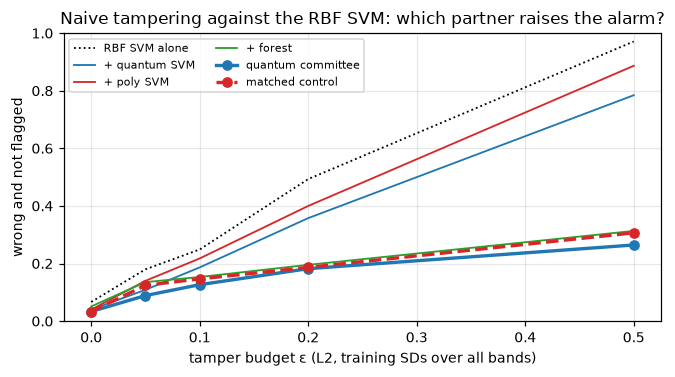

Paired bootstrap of the undetected rate (second minus first; negative = second lets fewer through)


,attack,eps,first,second,delta,ci95,share_positive
0,naive,0.05,+ poly SVM,+ quantum SVM,-0.031,"[-0.093531, 0.016671]",0.100
1,naive,0.10,+ poly SVM,+ quantum SVM,-0.031,"[-0.084447, 0.016132]",0.084
2,naive,0.20,+ poly SVM,+ quantum SVM,-0.042,"[-0.132135, 0.025137]",0.114
3,naive,0.50,+ poly SVM,+ quantum SVM,-0.102,"[-0.169043, -0.045659]",0.000
4,naive,0.05,matched control,quantum committee,-0.036,"[-0.086498, 0.005995]",0.044
5,naive,0.10,matched control,quantum committee,-0.020,"[-0.049594, -0.002347]",0.000
6,naive,0.20,matched control,quantum committee,-0.004,"[-0.015724, 0.00509]",0.135
7,naive,0.50,matched control,quantum committee,-0.042,"[-0.094152, -0.004784]",0.012
8,adaptive,0.05,matched control,quantum committee,-0.038,"[-0.090929, 0.005594]",0.030
9,adaptive,0.10,matched control,quantum committee,-0.007,"[-0.025424, 0.0]",0.000


In [8]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for name, style in zip(alarms, ['k:', 'C0-', 'C3-', 'C2-', 'C0-o', 'C3--o']):
    g = naive[naive.alarm == name].groupby('eps').undetected.mean()
    ax.plot(g.index, g.values, style, lw=2.2 if 'o' in style else 1.2, label=name)
ax.set(xlabel='tamper budget ε (L2, training SDs over all bands)', ylabel='wrong and not flagged', ylim=(0, 1),
       title='Naive tampering against the RBF SVM: which partner raises the alarm?')
ax.legend(fontsize=7, ncol=2); save_show(fig, 'cg_03_tamper_alarm')
print('Paired bootstrap of the undetected rate (second minus first; negative = second lets fewer through)')
display(pd.DataFrame(lab['bootstrap'])[['attack', 'eps', 'first', 'second', 'delta', 'ci95', 'share_positive']].round(3))

In [9]:
pr = pd.DataFrame(lab['poison_rows'])
print('Poisoned training labels: validation macro-F1, mean of the draws')
display(pr.pivot_table(index='model', columns='rate', values='macro_f1').loc[order[:2] + order[3:]].round(3))
mr = pd.DataFrame(lab['missing_rows'])
print('Missing bands at prediction time: macro-F1 and alarm, mean of the draws')
display(mr[mr.macro_f1.notna()].pivot_table(index='model', columns='missing', values='macro_f1').loc[order[:2] + order[3:]].round(3))
display(mr[mr.macro_f1.isna()].pivot_table(index='model', columns='missing', values=['flagged', 'undetected']).round(3))

Poisoned training labels: validation macro-F1, mean of the draws


rate,0.1,0.2,0.3
model,,,
quantum committee,0.892,0.880,0.844
matched control,0.889,0.885,0.856
quantum SVM,0.862,0.829,0.783
poly SVM,0.878,0.878,0.845
RBF SVM,0.900,0.880,0.841
forest,0.879,0.868,0.849


Missing bands at prediction time: macro-F1 and alarm, mean of the draws


missing,1,2,4
model,,,
quantum committee,0.825,0.765,0.667
matched control,0.808,0.743,0.632
quantum SVM,0.752,0.671,0.564
poly SVM,0.775,0.696,0.572
RBF SVM,0.796,0.717,0.605
forest,0.869,0.842,0.777


flagged               undetected              
missing                       1      2      4          1      2      4
model                                                                 
matched control alarm     0.219  0.307  0.431      0.059  0.064  0.085
quantum committee alarm   0.270  0.383  0.519      0.056  0.057  0.067

## 6. Additional analysis: quantum noise and the AI error-fixer (needs `qiskit-aer`)

A real device returns noisy similarity values. Because the circuits are small enough to simulate exactly, the true value of any training pair is known, so a **linear regression learns noisy → exact** on calibration pairs and corrects pairs it never saw. Zero-noise extrapolation (ZNE, every CX tripled, then extrapolated to zero noise) is the classical baseline; it costs twice the circuits.

The simulated device uses **real calibration data** of the IBM QPU named in `configs/experiment.json` (`noise.device`): median gate errors and durations, readout error and T1/T2, read live from IBM (saved in `outputs/device_profile.json`) or, offline, from IBM's calibration snapshot of that device. Levels 2× and 3× multiply those error rates.

,device calibration used
device,ibm_fez
retrieved_utc,2026-11-20T11:02:17+00:00
qubits,156
two_qubit_gate,cz
sx_error,0.000301
sx_seconds,0.0
two_qubit_error,0.002454
two_qubit_seconds,0.0
readout_error,0.010437
t1_seconds,0.00013


,mae_raw,mae_zne,mae_fixed,fixer_slope,fixer_intercept,f1_exact,f1_raw,f1_fixed,circuits,depth,cx
level,,,,,,,,,,,
1,0.0523,0.0318,0.0108,1.1967,-0.0002,0.6,0.7209,0.7209,3380,51,28
2,0.0956,0.0629,0.0129,1.4294,-0.0014,0.6,0.7209,0.6351,3380,51,28
3,0.1314,0.0943,0.0151,1.7052,-0.0025,0.6,0.6645,0.6351,3380,51,28


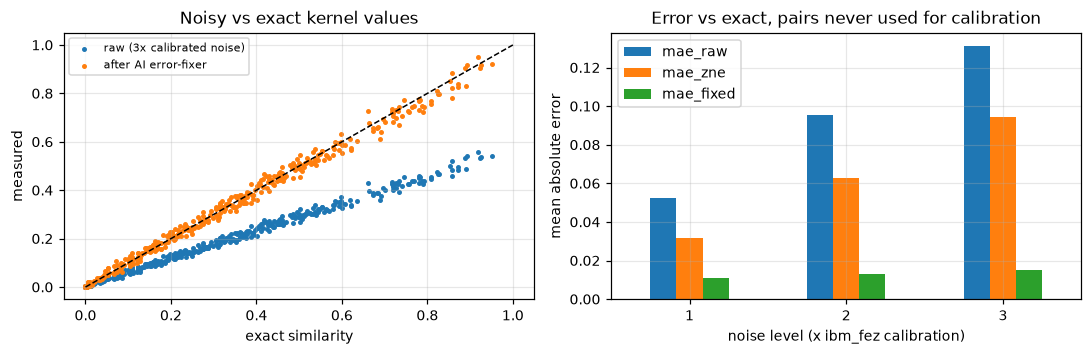

In [10]:
try:
    import qiskit_aer  # optional extra: requirements-noise.txt
    have_aer = True
except ImportError:
    have_aer = False
if RUN_NOISE_STUDY and have_aer:
    profile = mitigation.load_profile()
    q0 = fitted['quantum committee', first]
    noise, noise_s = timed(lambda: mitigation.noise_study(q0.members[0], q0.transform(X), y, q0.transform(Xv), yv, profile))
    noise['seconds'] = noise_s
    (OUT / 'noise_study.json').write_text(json.dumps(noise))
else:
    print('qiskit-aer not installed or study switched off: showing the saved study')
    noise = json.loads((OUT / 'noise_study.json').read_text())
display(pd.Series(noise['profile'], name='device calibration used').to_frame())
nr = pd.DataFrame(noise['rows']).set_index('level')
display(nr[['mae_raw', 'mae_zne', 'mae_fixed', 'fixer_slope', 'fixer_intercept', 'f1_exact', 'f1_raw', 'f1_fixed', 'circuits', 'depth', 'cx']].round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
r = noise['rows'][-1]
axes[0].scatter(r['sample_exact'], r['sample_raw'], s=5, label=f"raw ({r['level']}x calibrated noise)")
axes[0].scatter(r['sample_exact'], r['sample_fixed'], s=5, label='after AI error-fixer')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1); axes[0].set(xlabel='exact similarity', ylabel='measured', title='Noisy vs exact kernel values'); axes[0].legend(fontsize=7)
nr[['mae_raw', 'mae_zne', 'mae_fixed']].plot.bar(ax=axes[1], rot=0)
axes[1].set(xlabel=f"noise level (x {noise['profile']['device']} calibration)", ylabel='mean absolute error',
            title='Error vs exact, pairs never used for calibration')
fig.tight_layout(); save_show(fig, 'cg_04_noise_fixer')

## 7. IBM hardware bonus: inference only, compared with the exact simulator

The committee is trained locally and frozen; the QPU only measures the compute-uncompute similarity circuits between a few validation fields and the quantum SVM's support vectors. Nothing is trained on hardware. Fields: one typical verified field per crop and one tampered field that fools the RBF SVM while the exact quantum SVM still answers correctly (so the alarm fires). Calibration pairs of training fields ride in the same job, so the AI error-fixer is fitted **on that device in that session**. Shots, calibration pairs and the tamper budget come from `configs/experiment.json` (`hardware`). The token is read from `QISKIT_IBM_TOKEN` only; it never appears in this notebook, the outputs or git.

The first run uses the **submitted** model. An offline scan then uses that run's measured errors to choose a hardware-ready C (the largest C that keeps at least `hardware.min_vote_agreement` of votes), and a second run checks it. **One small fixed-model inference example per model, not an accuracy estimate.**

,support_vectors,max_dual,exact_macro_f1,agree_shot_noise,agree_hardware_error
C,,,,,
0.3,395,0.3,0.893,0.993,0.985
1.0,300,1.0,0.893,0.978,0.969
3.0,265,3.0,0.900,0.934,0.891
10.0,230,10.0,0.913,0.810,0.721
30.0,225,30.0,0.920,0.628,0.566
100.0,222,100.0,0.920,0.490,0.432


hardware-ready C by the rule: 1
saved hardware-ready run used C = 1 | rule now gives 1


,hardware_result.json,hardware_result_robust.json
backend,ibm_fez,ibm_marrakesh
job_id,dc01nteq4uuc73a1tkq0,dc01qrts2omc7388k9h0
finished_utc,2026-11-20T10:11:03+00:00,2026-11-20T10:18:02+00:00
quantum_params,"{'scale': 0.075, 'C': 100}","{'scale': 0.075, 'C': 1}"
shots,512,512
circuits,928,1240
support_vectors,222,300
calibration_pairs,40,40
transpiled_depth,102,99
transpiled_two_qubit_gates,26,26


name   target  \
hardware_result.json        0             clean alfalfa  alfalfa   
                            1               clean maize    maize   
                            2               clean wheat    wheat   
                            3  tampered wheat (eps 0.1)    wheat   
hardware_result_robust.json 0             clean alfalfa  alfalfa   
                            1               clean maize    maize   
                            2               clean wheat    wheat   
                            3  tampered wheat (eps 0.1)    wheat   

                              quantum_exact quantum_hardware_raw  \
hardware_result.json        0       alfalfa              alfalfa   
                            1         maize              alfalfa   
                            2         wheat              alfalfa   
                            3         wheat                maize   
hardware_result_robust.json 0       alfalfa              alfalfa   
                            1         maize                maize   
                            2         wheat                wheat   
                            3         wheat                maize   

                              quantum_hardware_fixed      rbf   forest  
hardware_result.json        0                alfalfa  alfalfa  alfalfa  
                            1                alfalfa    maize    maize  
                            2                alfalfa    wheat    wheat  
                            3                  maize  alfalfa  alfalfa  
hardware_result_robust.json 0                alfalfa  alfalfa  alfalfa  
                            1                  maize    maize    maize  
                            2                  wheat    wheat    wheat  
                            3                  wheat    maize    maize

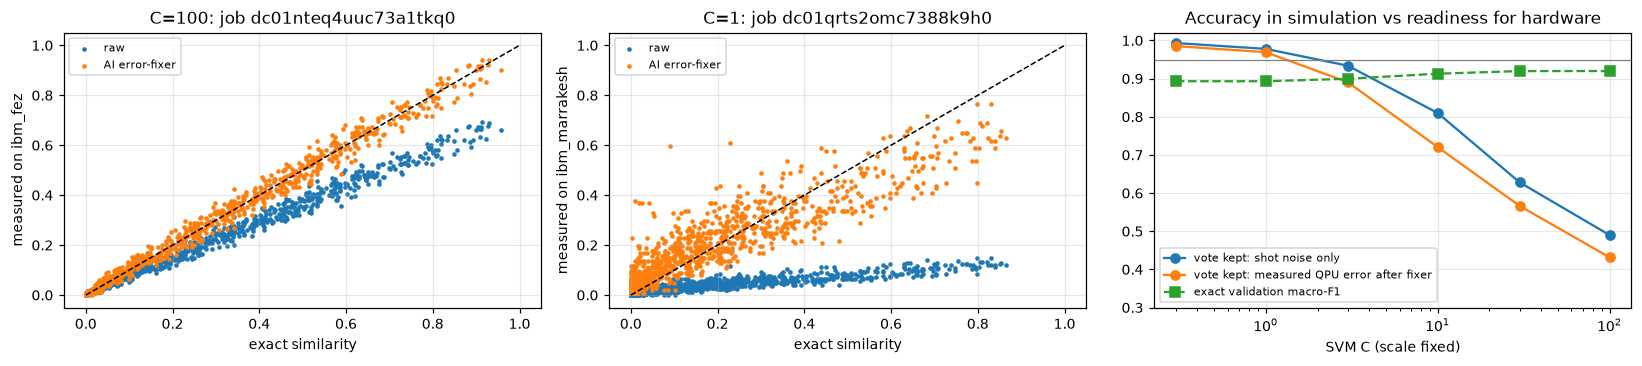

In [11]:
model0 = fitted['quantum committee', first]
if RUN_HARDWARE:
    backend = hk.connect()
    mitigation.save_profile(backend)  # refresh the real calibration used by section 6
    hk.run(model0, hk.pick_fields(model0, X, Xv, yv, ids_v), backend, approved=True, save=OUT / 'hardware_result.json')
hw = json.loads((OUT / 'hardware_result.json').read_text())

# Why might the submitted model's votes not survive the QPU? Large C means large dual coefficients that amplify kernel
# errors. Offline (no QPU): resample this run's measured post-fixer errors, or shot-sampling noise, for every candidate C.
scan = hk.robustness_scan(Z, y, Zv, yv, hk.residuals(hw), model0.members[0].scale)
chosen = hk.choose_C(scan)
(OUT / 'hardware_robustness.json').write_text(json.dumps(dict(rows=scan, chosen_C=chosen, source='hardware_result.json residuals after the AI error-fixer'), indent=1))
sc = pd.DataFrame(scan).set_index('C'); display(sc.round(3))
print('hardware-ready C by the rule:', chosen)

if RUN_HARDWARE and chosen is not None:
    cfg = load_config(); cfg['quantum'] = dict(cfg['quantum'], C=chosen)
    model1 = Submission(cfg).fit(X, y, first)
    hk.run(model1, hk.pick_fields(model1, X, Xv, yv, ids_v), backend, approved=True, save=OUT / 'hardware_result_robust.json')
runs_hw = {f: json.loads((OUT / f).read_text()) for f in ['hardware_result.json', 'hardware_result_robust.json'] if (OUT / f).exists()}
if 'hardware_result_robust.json' in runs_hw:
    print('saved hardware-ready run used C =', runs_hw['hardware_result_robust.json']['quantum_params']['C'], '| rule now gives', chosen)

keys = ['backend', 'job_id', 'finished_utc', 'quantum_params', 'shots', 'circuits', 'support_vectors', 'calibration_pairs',
        'transpiled_depth', 'transpiled_two_qubit_gates', 'physical_qubits', 'quantum_seconds', 'mae_raw', 'mae_fixed', 'fixer_slope', 'fixer_intercept']
display(pd.DataFrame({f: {k: h.get(k) for k in keys} for f, h in runs_hw.items()}).astype(str))
display(pd.concat({f: pd.DataFrame(h['fields'])[['name', 'target', 'quantum_exact', 'quantum_hardware_raw', 'quantum_hardware_fixed', 'rbf', 'forest']]
                   for f, h in runs_hw.items()}))
fig, axes = plt.subplots(1, len(runs_hw) + 1, figsize=(5 * (len(runs_hw) + 1), 3.4))
for ax, (f, h) in zip(axes, runs_hw.items()):
    n = h['support_vectors'] * len(h['fields']); ex, me = np.array(h['exact']), np.array(h['measured'])
    ax.scatter(ex[:n], me[:n], s=4, label='raw')
    ax.scatter(ex[:n], np.clip(h['fixer_slope'] * me[:n] + h['fixer_intercept'], 0, 1), s=4, label='AI error-fixer')
    ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.legend(fontsize=7)
    ax.set(xlabel='exact similarity', ylabel=f"measured on {h['backend']}", title=f"C={h['quantum_params']['C']}: job {h['job_id']}")
ax = axes[-1]
ax.semilogx(sc.index, sc.agree_shot_noise, 'o-', label='vote kept: shot noise only')
ax.semilogx(sc.index, sc.agree_hardware_error, 'o-', label='vote kept: measured QPU error after fixer')
ax.semilogx(sc.index, sc.exact_macro_f1, 's--', label='exact validation macro-F1')
ax.axhline(EXPERIMENT['hardware']['min_vote_agreement'], color='grey', lw=.8)
ax.set(xlabel='SVM C (scale fixed)', ylim=(0.3, 1.02), title='Accuracy in simulation vs readiness for hardware'); ax.legend(fontsize=7)
fig.tight_layout(); save_show(fig, 'cg_05_ibm_hardware')

## 8. Findings

The next cell writes the findings from the results above with [`challenge/report.py`](../challenge/report.py), so every number and every "detectable / not detectable" verdict follows the data.

In [12]:
display(Markdown(report.findings(main=main, lab=lab, noise=noise, hw=hw, robust=runs_hw.get('hardware_result_robust.json'),
                                 scan=scan, chosen=chosen, runtime=time.perf_counter() - T0)))

**Answer.** On clean data: no detectable difference between the quantum committee and an equally tuned classical one. Under tampering, the partner that protects most is the forest.

1. **Clean comparison (main result).** Quantum committee 0.9214 ± 0.0033 macro-F1 (92.2% accuracy) vs matched control 0.9218 ± 0.0032; paired bootstrap -0.0004, 95% interval [-0.019, +0.024]: no detectable difference. Against the supplied reference (0.8797) the quantum committee differs by +0.042 [-0.001, +0.092] (interval includes zero). The best single model is the RBF SVM (0.933); quantum committee minus RBF SVM -0.011 [-0.032, +0.005]. The alarm flags 9.1% of clean fields, and 96.3% of the unflagged ones are right.

2. **Tampering and the alarm** (naive attacker aiming at the RBF SVM). At ε = 0.1, 24.9% of fields slip through the RBF SVM alone, 18.7% with a quantum partner, 21.8% with a polynomial partner, 15.3% with the forest, 12.7% through the full quantum committee and 14.7% through the matched control; the quantum committee flags 19.1% vs 13.6%. Paired bootstrap, quantum minus control: ε = 0.05: -0.036 [-0.086, +0.006]; ε = 0.1: -0.020 [-0.050, -0.002]; ε = 0.2: -0.004 [-0.016, +0.005]; ε = 0.5: -0.042 [-0.094, -0.005] (2 of 4 intervals exclude zero; 12 comparisons in total, so read single intervals with care). At ε = 0.2 the partner that cuts slips most is the forest (49.3% → 19.6%; quantum SVM 35.8%, poly SVM 40.0%, forest 19.6%). An attacker who knows all three inspectors gets 50.4% (quantum) and 54.9% (control) of fields through at ε = 0.5.

3. **Single inspectors.** On fields tampered against the RBF SVM (ε = 0.1) the quantum SVM keeps 0.738 accuracy vs 0.738 for the poly SVM. With 30.0% poisoned labels: quantum SVM 0.783, poly SVM 0.845, RBF SVM 0.841, forest 0.849 (lowest: quantum SVM). With 4 bands missing: quantum SVM 0.564, poly SVM 0.572, RBF SVM 0.605, forest 0.777 (lowest: quantum SVM). Committees: 0.844 / 0.856 with poisoning and 0.667 / 0.632 with missing bands (quantum committee flags 51.9% vs 43.1%). Descriptive only: no bootstrap was run for poisoning or missing bands.

4. **AI error-fixer on a simulated device built from real calibration** (ibm_fez, retrieved 2026-11-20T11:02:17+00:00: two-qubit error 0.25%, single-qubit 0.03%, readout 1%, T1 130 µs, T2 95 µs). Similarity error vs exact, raw → fixed: 1× 0.052 → 0.011 (ZNE 0.032); 2× 0.096 → 0.013 (ZNE 0.063); 3× 0.131 → 0.015 (ZNE 0.094). One straight line fitted on 200 calibration pairs; ZNE costs twice the circuits. The 30-field classification check is too small to support any accuracy claim. Realism check: the median-calibration model predicts a raw error of 0.052 at 1×; the real ibm_fez run measured 0.073 (different field pairs, and the real device adds per-qubit spread, crosstalk and drift).

5. **IBM hardware (inference only).** `ibm_fez` (job `dc01nteq4uuc73a1tkq0`, submitted model, C = 100): the in-job error-fixer took the kernel error from 0.073 to 0.018; 1 of 4 quantum votes matched the exact simulator. Offline scan: shot noise alone keeps 49.0% of this model's votes (43.2% under the measured hardware error), because large C means large dual weights that amplify kernel errors. Rule: the largest C keeping at least 95.0% of votes under the measured error → C = 1 (96.9%; exact macro-F1 0.893 instead of 0.920). `ibm_marrakesh` (job `dc01qrts2omc7388k9h0`, C = 1): 4 of 4 votes matched. On the tampered field the raw hardware vote was wrong (maize) and the error-fixer restored it (wheat), so the alarm fired on a real device. One small inference example per model, not an accuracy estimate.

6. **Tuning effort.** quantum: 30 configurations in 2.9 s, poly: 30 configurations in 1.0 s, rbf: 30 configurations in 0.9 s, forest: 30 configurations in 26.2 s (validation macro-F1; `outputs/tuning_log.json`).

7. **Runtime.** Main run 40 s; whole notebook 477 s.

**Limitations.** Settings were chosen and scored on the same validation fields. Attacks are a weak gradient-free search within the training range; NDVI is not kept consistent with B4/B8. The noise study is a uniform device built from median calibration on a small subset; real devices add per-qubit spread, crosstalk and drift, so the error-fixer must be recalibrated each session (we did so inside each job). The error-fixer needs exact simulation for its labels, which works only for small circuits. Results cover one region, one date and three crops.

**We do not claim** a quantum advantage of any kind; that the quantum model is more robust than a classical one; that the alarm stops an attacker who knows the defence; that the error-fixer improves final accuracy; or that the hardware runs measure accuracy.

**Reused code and methods.** Organizers' starter (`challenge/data.py`, `classical.py`, `metrics.py`, `coverage.py`; `metric_vector` reused for the bootstrap). Qiskit `zz_feature_map` and `Statevector` (our closed form is checked against them in `tests/`), scikit-learn, qiskit-aer, qiskit-ibm-runtime (device calibration and execution). Quantum kernels: Havlíček et al. 2019; classical–quantum ensembles: Grossi et al. 2022; shot noise and SVM robustness: Shastry et al. 2022; learned error mitigation: Czarnik et al. 2020, Liao et al. 2023; benchmarking practice: Bowles et al. 2024; adversarial remote sensing: Czaja et al. 2018. Links in the README.

In [13]:
print(f'notebook total runtime: {time.perf_counter() - T0:.0f} s')
print('outputs:', sorted(p.name for p in OUT.glob('*.json')), '| predictions:', len(list((OUT / 'predictions').glob('*.csv'))), 'csv files')

notebook total runtime: 477 s
outputs: ['attack_lab.json', 'device_profile.json', 'hardware_result.json', 'hardware_result_robust.json', 'hardware_robustness.json', 'main_results.json', 'noise_study.json', 'tuning_log.json'] | predictions: 27 csv files
